In [67]:
import pandas as pd, os, json, numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor
)
from xgboost import XGBRegressor
from sklearn.model_selection import KFold, cross_val_score
import matplotlib.pyplot as plt

In [36]:
path="../data/property_price_data.csv"
df=pd.read_csv(path)
#df.shape, df.columns.tolist(), df.head(), df.dtypes
df = df.dropna(subset=["price_data_7"])
df.isnull().sum()

In [37]:
df["future_growth"] = (
    (df["price_data_7"] - df["price_data_6"])
    / df["price_data_6"]
) * 100

target = "future_growth"

# Exclude price and growth data 7 (target value)
features = [
    "price_data_1",
    "price_data_2",
    "price_data_3",
    "price_data_4",
    "price_data_5",
    "price_data_6",
    
    "growth_data_2",
    "growth_data_3",
    "growth_data_4",
    "growth_data_5",
    "growth_data_6",
    
    "crime_rate",
    "hh_income",
    "council_tax_rate"
]

X = df[features]
y = df[target]

baseline_predictions = df["price_data_6"]
actual = df["price_data_7"]

In [38]:
baseline_mae = mean_absolute_error(actual, baseline_predictions)
baseline_rmse = np.sqrt(
    mean_squared_error(actual, baseline_predictions)
)

print("Baseline MAE:", baseline_mae)
print("Baseline RMSE:", baseline_rmse)

Baseline MAE: 14801.962577962579
Baseline RMSE: 22754.225198923526


In [39]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Testing different models

In [40]:
linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

linear_mae = mean_absolute_error(
    y_test,
    linear_predictions
)

linear_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        linear_predictions
    )
)

linear_r2 = r2_score(
    y_test,
    linear_predictions
)

print(f"Linear Regression MAE: £{linear_mae:,.2f}")
print(f"Linear Regression RMSE: £{linear_rmse:,.2f}")
print(f"Linear Regression R²: {linear_r2:.4f}")

Linear Regression MAE: £4.69
Linear Regression RMSE: £6.72
Linear Regression R²: 0.0591


In [41]:
rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=10,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

rf_mae = mean_absolute_error(
    y_test,
    rf_predictions
)

rf_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        rf_predictions
    )
)

rf_r2 = r2_score(
    y_test,
    rf_predictions
)

print(f"Random Forest MAE: £{rf_mae:,.2f}")
print(f"Random Forest RMSE: £{rf_rmse:,.2f}")
print(f"Random Forest R²: {rf_r2:.4f}")

Random Forest MAE: £4.06
Random Forest RMSE: £6.30
Random Forest R²: 0.1742


In [42]:
baseline_test_predictions = df.loc[
    y_test.index,
    "price_data_6"
]

baseline_test_mae = mean_absolute_error(
    y_test,
    baseline_test_predictions
)

baseline_test_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        baseline_test_predictions
    )
)

baseline_test_r2 = r2_score(
    y_test,
    baseline_test_predictions
)

print(f"Baseline Test MAE: £{baseline_test_mae:,.2f}")
print(f"Baseline Test RMSE: £{baseline_test_rmse:,.2f}")
print(f"Baseline Test R²: {baseline_test_r2:.4f}")

Baseline Test MAE: £336,563.52
Baseline Test RMSE: £368,016.18
Baseline Test R²: -2821016555.9272


In [43]:
results = pd.DataFrame({
    "Model": [
        "Previous Period Baseline",
        "Linear Regression",
        "Random Forest"
    ],
    "MAE": [
        baseline_test_mae,
        linear_mae,
        rf_mae
    ],
    "RMSE": [
        baseline_test_rmse,
        linear_rmse,
        rf_rmse
    ],
    "R2": [
        baseline_test_r2,
        linear_r2,
        rf_r2
    ]
})

results

,Model,MAE,RMSE,R2
0,Previous Period Baseline,336563.519854,368016.184597,-2.821017e+09
1,Linear Regression,4.687793,6.721093,5.908240e-02
2,Random Forest,4.059447,6.296558,1.741935e-01


In [44]:
rf_improvement = (
    (baseline_test_mae - rf_mae)
    / baseline_test_mae
) * 100

print(
    f"Random Forest improvement over baseline: "
    f"{rf_improvement:.2f}%"
)

Random Forest improvement over baseline: 100.00%


In [69]:
X = df[historical_features]
y = df["future_growth"]

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models = {
    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        max_depth=10,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ),

    "Hist Gradient Boosting": HistGradientBoostingRegressor(
        learning_rate=0.05,
        max_iter=200,
        max_depth=5,
        random_state=42
    ),
    "XG Boosing": XGBRegressor(
        n_estimators=300,
        learning_rate=0.03,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42
    )
}

results = []

for name, model in models.items():

    scores = cross_val_score(
        model,
        X,
        y,
        cv=cv,
        scoring="neg_mean_absolute_error"
    )

    mae_scores = -scores

    results.append({
        "Model": name,
        "Mean CV MAE": mae_scores.mean(),
        "Std CV MAE": mae_scores.std()
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values("Mean CV MAE")

results_df

,Model,Mean CV MAE,Std CV MAE
1,Random Forest,3.484978,0.357216
4,XG Boosing,3.512752,0.446512
3,Hist Gradient Boosting,3.608707,0.505343
2,Gradient Boosting,3.661685,0.410513
0,Linear Regression,4.177396,0.379884


# Feature Testing

In [46]:
importance = pd.DataFrame({
    "Feature": features,
    "Importance": rf_model.feature_importances_
}).sort_values(
    "Importance",
    ascending=False
)

importance

,Feature,Importance
6,growth_data_2,0.199449
10,growth_data_6,0.168616
5,price_data_6,0.091492
9,growth_data_5,0.089627
8,growth_data_4,0.083987
12,hh_income,0.083778
7,growth_data_3,0.080908
0,price_data_1,0.053083
4,price_data_5,0.038648
1,price_data_2,0.035888


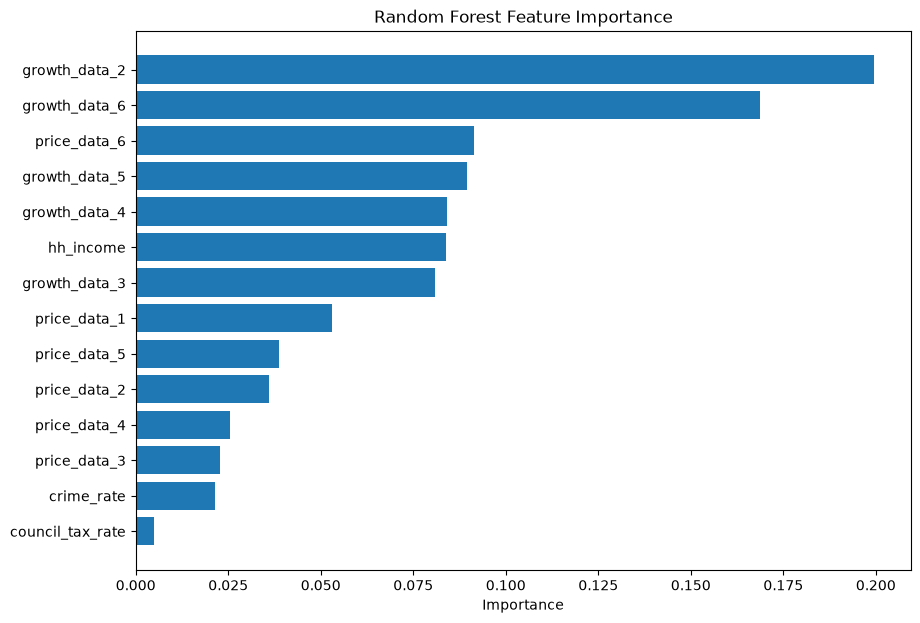

In [47]:
plt.figure(figsize=(10, 7))

plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.gca().invert_yaxis()

plt.xlabel("Importance")
plt.title("Random Forest Feature Importance")

plt.show()

In [49]:
check_cols = [
    "growth_data_2",
    "growth_data_3",
    "growth_data_4",
    "growth_data_5",
    "growth_data_6",
    "future_growth"
]

df[check_cols].corr()["future_growth"].sort_values(ascending=False)

future_growth    1.000000
growth_data_2    0.260241
growth_data_5    0.045601
growth_data_3   -0.028464
growth_data_4   -0.032661
growth_data_6   -0.284949
Name: future_growth, dtype: float64

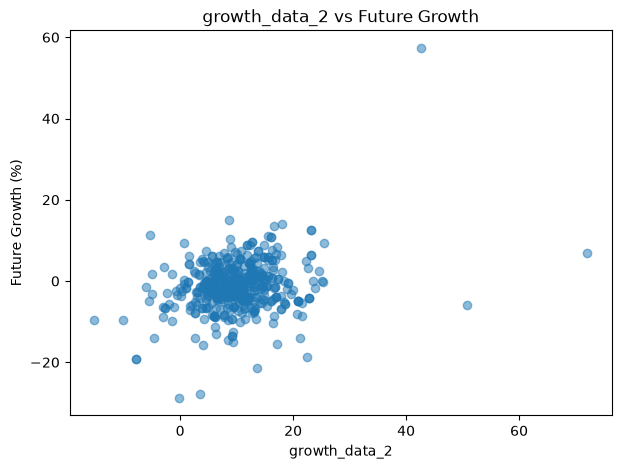

In [50]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7,5))
plt.scatter(
    df["growth_data_2"],
    df["future_growth"],
    alpha=0.5
)

plt.xlabel("growth_data_2")
plt.ylabel("Future Growth (%)")
plt.title("growth_data_2 vs Future Growth")
plt.show()

In [53]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    rf_model,
    X_test,
    y_test,
    n_repeats=20,
    random_state=42,
    scoring="neg_mean_absolute_error"
)

perm_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": perm.importances_mean
}).sort_values(
    "Importance",
    ascending=False
)

perm_importance

,Feature,Importance
10,growth_data_6,0.784547
7,growth_data_3,0.162421
1,price_data_2,0.150266
9,growth_data_5,0.145462
5,price_data_6,0.122626
8,growth_data_4,0.105819
0,price_data_1,0.085915
6,growth_data_2,0.077987
12,hh_income,0.057057
4,price_data_5,0.046081


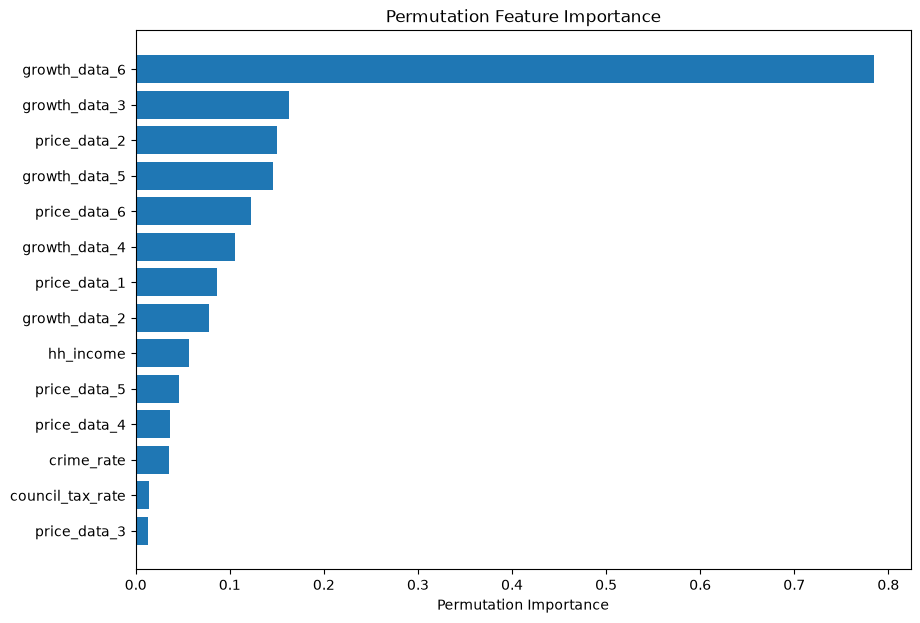

In [54]:
plt.figure(figsize=(10,7))

plt.barh(
    perm_importance["Feature"],
    perm_importance["Importance"]
)

plt.gca().invert_yaxis()
plt.xlabel("Permutation Importance")
plt.title("Permutation Feature Importance")

plt.show()

In [55]:
historical_features = [
    "price_data_1",
    "price_data_2",
    "price_data_3",
    "price_data_4",
    "price_data_5",
    "price_data_6",
    "growth_data_2",
    "growth_data_3",
    "growth_data_4",
    "growth_data_5",
    "growth_data_6"
]

area_features = [
    "crime_rate",
    "hh_income",
    "council_tax_rate"
]

full_features = historical_features + area_features

In [56]:
X_hist = df[historical_features]
y = df["future_growth"]

X_train_h, X_test_h, y_train_h, y_test_h = train_test_split(
    X_hist,
    y,
    test_size=0.2,
    random_state=42
)

rf_hist = RandomForestRegressor(
    n_estimators=300,
    max_depth=10,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

rf_hist.fit(X_train_h, y_train_h)

hist_predictions = rf_hist.predict(X_test_h)

hist_mae = mean_absolute_error(
    y_test_h,
    hist_predictions
)

print(f"Historical-only MAE: {hist_mae:.3f} percentage points")

Historical-only MAE: 4.024 percentage points


In [57]:
X_full = df[full_features]

X_train_f, X_test_f, y_train_f, y_test_f = train_test_split(
    X_full,
    y,
    test_size=0.2,
    random_state=42
)

rf_full = RandomForestRegressor(
    n_estimators=300,
    max_depth=10,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

rf_full.fit(X_train_f, y_train_f)

full_predictions = rf_full.predict(X_test_f)

full_mae = mean_absolute_error(
    y_test_f,
    full_predictions
)

print(f"Historical + area MAE: {full_mae:.3f} percentage points")

Historical + area MAE: 4.059 percentage points


In [58]:
improvement = (
    (hist_mae - full_mae)
    / hist_mae
) * 100

print(f"Improvement from area features: {improvement:.2f}%")

Improvement from area features: -0.88%


In [59]:
test_features = {
    "historical_only": historical_features,
    "historical + crime": historical_features + ["crime_rate"],
    "historical + income": historical_features + ["hh_income"],
    "historical + council_tax": historical_features + ["council_tax_rate"],
    "historical + crime + income": historical_features + [
        "crime_rate",
        "hh_income"
    ],
    "historical + all_area": historical_features + [
        "crime_rate",
        "hh_income",
        "council_tax_rate"
    ]
}

results = []

for name, features in test_features.items():

    X = df[features]
    y = df["future_growth"]

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42
    )

    model = RandomForestRegressor(
        n_estimators=300,
        max_depth=10,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    mae = mean_absolute_error(
        y_test,
        predictions
    )

    results.append({
        "Model": name,
        "MAE": mae
    })

results_df = pd.DataFrame(results)

results_df.sort_values("MAE")

,Model,MAE
3,historical + council_tax,4.006798
1,historical + crime,4.013925
0,historical_only,4.023956
2,historical + income,4.055711
5,historical + all_area,4.059447
4,historical + crime + income,4.067337


In [61]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=10,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

scores = cross_val_score(
    rf,
    df[historical_features],
    df["future_growth"],
    cv=cv,
    scoring="neg_mean_absolute_error"
)

historical_cv_mae = -scores.mean()

print(
    f"Historical-only CV MAE: "
    f"{historical_cv_mae:.3f}"
)

Historical-only CV MAE: 3.485


In [62]:
scores_full = cross_val_score(
    rf,
    df[full_features],
    df["future_growth"],
    cv=cv,
    scoring="neg_mean_absolute_error"
)

full_cv_mae = -scores_full.mean()

print(
    f"Historical + area CV MAE: "
    f"{full_cv_mae:.3f}"
)

Historical + area CV MAE: 3.519


In [63]:
cv_improvement = (
    historical_cv_mae - full_cv_mae
) / historical_cv_mae * 100

print(
    f"Cross-validated improvement: "
    f"{cv_improvement:.2f}%"
)

Cross-validated improvement: -0.99%


In [70]:
X = df[historical_features]
y = df["future_growth"]

final_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=10,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

final_model.fit(X, y)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",3
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max

In [71]:
import joblib

joblib.dump(
    final_model,
    "../models/future_growth_rf.pkl"
)

['../models/future_growth_rf.pkl']